# Sample-Based Krylov Quantum Diagonalization (SKQD)

SKQD [[1](#skqd)] estimates the **ground-state energy** of a Hamiltonian $H$. It is a hybrid
quantum–classical alternative to Quantum Phase Estimation (QPE), designed for
pre-fault-tolerant hardware.

QPE, the textbook quantum algorithm for eigenvalue estimation, is for now out of reach: it
requires circuits far too deep for current, noisy hardware. This has motivated a search for
shallower, near-term alternatives. One promising family is the **subspace diagonalization**
algorithms, in which a quantum module identifies a low-dimensional subspace of the Hilbert space
expected to contain most of the ground state's weight, and a classical module then diagonalizes
$H$ restricted to that subspace. These methods differ in how the quantum module builds the
subspace. In **Krylov quantum diagonalization (KQD)** [[2](#kqd)], it is spanned by time-evolving a
reference state over a range of time intervals. In **sample-based quantum diagonalization (SQD)**, it is spanned by
sampling a reference state in the computational basis (see [[3](#sqd)] for example).

**Sample-based Krylov quantum diagonalization (SKQD)** [[1](#skqd)], which we implement in this notebook, draws
on both: a well-chosen reference state is time-evolved over several time intervals, and each evolved
state is then sampled in the computational basis. The sampled bitstrings define the subspace in
which we classically diagonalize $H$.

Like KQD, SKQD comes with a **polynomial-time convergence guarantee** (under certain assumptions we mention below), but it
uses shallower circuits than KQD, and the sampling makes it more robust to noise.

In this notebook we implement SKQD, using the **single-impurity Anderson model (SIAM)** [[4](#anderson)] as a worked
example.

## The idea

Starting from a reference state $|\psi_0\rangle$, real-time evolution generates the
**Krylov states**

$$|\psi_k\rangle = e^{-iH\,k\,\Delta t}\,|\psi_0\rangle, \qquad k = 0, 1, \dots, D-1 .$$

Their span is a Krylov subspace that, provided $|\psi_0\rangle$ has sufficient overlap
with the true ground state,  captures the low-energy physics, so diagonalizing $H$
restricted to that subspace gives a good ground-energy estimate.

The **sample-based** twist avoids measuring overlaps with Hadamard tests. Instead we
sample each $|\psi_k\rangle$ in the computational basis, collect the set
$\mathcal{S}$ of observed bitstrings,
and diagonalize $H$ projected onto $\mathrm{span}(\mathcal{S})$.


Informally, the main assumptions are (the full convergence analysis is considerably more intricate,
and can be found in [[1](#skqd)]):

1. **Ground-state overlap.** The reference $|\psi_0\rangle$ needs appreciable overlap with the
   true ground state; the smaller the overlap, the more Krylov vectors and shots are needed.
2. **Ground-state sparsity.** The ground state must be reasonably sparse in the computational
   basis, so that sampling actually collects the few configurations that carry its weight.

**Complexity.** Made quantitative (inverse-polynomial overlap and a polynomially sparse ground state), these assumptions yield a polynomial-time ground-energy estimate [[1](#skqd)].

The notebook first builds a generic time-evolution core, then instantiates it on the SIAM
example — constructing the Hamiltonian, mapping it to qubits, and preparing a Hartree–Fock
reference — and finally samples the Krylov states and diagonalizes $H$ in the sampled subspace.

In [245]:
!pip install -qq "classiq[chemistry]"

zsh:1: command not found: pip


In [246]:
import numpy as np

from classiq import *

## Time evolution: building the Krylov states

The quantum heart of SKQD is building the Krylov states
$|\psi_k\rangle = e^{-iH\,(k\,\Delta t)}\,|\psi_0\rangle$. We approximate the evolution $e^{-iHt}$ by a **Suzuki–Trotter** product, using
Classiq's built-in [`suzuki_trotter`](https://docs.classiq.io/qmod-reference/library-reference/core-library-functions/hamiltonian_evolution/suzuki_trotter/suzuki_trotter).
The reference state enters through a pluggable `state_prep` argument so it can be swapped later; the
concrete `main` is assembled further down.

In [247]:
@qfunc
def krylov_evolve(
    hamiltonian: SparsePauliOp,
    evolution_time: CReal,
    order: CInt,
    repetitions: CInt,
    qba: QArray[QBit],
) -> None:
    """Apply e^{-i H t} to `qba`, approximated by a Suzuki-Trotter product."""
    suzuki_trotter(
        hamiltonian,
        evolution_coefficient=evolution_time,
        order=order,
        repetitions=repetitions,
        qbv=qba,
    )


@qfunc
def krylov_state(
    state_prep: QCallable[QArray[QBit]],
    hamiltonian: SparsePauliOp,
    evolution_time: CReal,
    order: CInt,
    repetitions: CInt,
    qba: QArray[QBit],
) -> None:
    """Prepare |psi_0> via the supplied `state_prep`, then evolve to time t."""
    state_prep(qba)
    krylov_evolve(hamiltonian, evolution_time, order, repetitions, qba)

## The single-impurity Anderson model

The worked example is the **single-impurity Anderson model** [[4](#anderson)]: one impurity orbital
$d$ coupled to $L$ bath sites $k = 1, \dots, L$. With spin $\sigma \in \{\uparrow, \downarrow\}$,

$$
H = \epsilon_d \sum_\sigma n_{d\sigma}
  \;+\; U\, n_{d\uparrow} n_{d\downarrow}
  \;+\; \sum_{k=1}^{L}\sum_\sigma \epsilon_k\, n_{k\sigma}
  \;+\; \sum_{k=1}^{L}\sum_\sigma V_k \left(c_{d\sigma}^\dagger c_{k\sigma} + c_{k\sigma}^\dagger c_{d\sigma}\right),
$$

where $c^\dagger$ and $c$ are the fermionic creation and annihilation operators, $n = c^\dagger c$ is the number operator, $\epsilon_d$ the impurity level, $U$ the
on-site Coulomb interaction felt when the impurity is doubly occupied (repulsive for $U>0$, the regime we use), $\epsilon_k$ the bath
energies, and $V_k$ the impurity–bath hybridization (hopping).

There are $2(L+1)$ spin-orbitals, hence a register of $N = 2(L+1)$ qubits (one qubit per spin-orbital). We index modes in a spin-blocked layout,

$$\text{mode}(o, \sigma) = \sigma\,(L+1) + o,$$

with orbital $o = 0$ the impurity and $o = 1, \dots, L$ the bath; spin $\sigma = 0$ (up),
$1$ (down).

We build $H$ as an `openfermion` `FermionOperator`. Any other
second-quantized Hamiltonian can be swapped in and fed to the time-evolution core above.


In [ ]:
from openfermion import FermionOperator

from classiq.applications.chemistry.mapping import FermionToQubitMapper
from classiq.applications.chemistry.op_utils import qubit_op_to_qmod
from classiq.applications.chemistry.problems import FermionHamiltonianProblem


def siam_fermion_hamiltonian(eps_d, U, eps_bath, V):
    """Single-impurity Anderson model as an openfermion FermionOperator.

    Args:
        eps_d:    impurity on-site energy
        U:        on-site Coulomb interaction on the impurity
        eps_bath: list of L bath on-site energies
        V:        list of L impurity-bath hybridizations

    Modes (spin-blocked): mode(orbital, spin) = spin*(L+1) + orbital,
    with orbital 0 = impurity and 1..L = bath; spin 0 = up, 1 = down.
    """
    L = len(eps_bath)
    assert len(V) == L, "need one hybridization V per bath site"

    def mode(orbital, spin):
        return spin * (L + 1) + orbital

    H = FermionOperator()  # zero operator
    for spin in (0, 1):
        d = mode(0, spin)
        H += FermionOperator(f"{d}^ {d}", eps_d)  # impurity level
        for k in range(1, L + 1):
            b = mode(k, spin)
            H += FermionOperator(f"{b}^ {b}", eps_bath[k - 1])  # bath level
            H += FermionOperator(f"{d}^ {b}", V[k - 1])  # hybridization d <- k
            H += FermionOperator(f"{b}^ {d}", V[k - 1])  # hybridization k <- d
    du, dd = mode(0, 0), mode(0, 1)
    H += FermionOperator(f"{du}^ {du} {dd}^ {dd}", U)  # Coulomb repulsion
    return H

### Mapping to a qubit Hamiltonian (Jordan–Wigner)

As the test case we take $L = 5$ bath sites with a **symmetric bath** (energies symmetric about
zero) at the **particle–hole symmetric point** ($\epsilon_d = -U/2$), at half filling (three spin-up
and three spin-down electrons). This is a 12-qubit model whose $(3,3)$ sector is 400-dimensional.

The Anderson Hamiltonian conserves the number of electrons of each spin, so it is block-diagonal in the $(n_\uparrow, n_\downarrow)$ sectors. Our reference has definite occupation numbers (the Hartree–Fock state, defined below). Real-time evolution then keeps every Krylov state in that one sector, and every sampled bitstring has exactly $n_\uparrow$ ($n_\downarrow$) occupied up- (down-) orbitals. SKQD therefore targets the ground state *within that sector*. For our half-filled $(3,3)$ choice at the particle–hole-symmetric point, this sector ground state **coincides with the global ground state**.

We map this fermionic Hamiltonian to qubits with the **Jordan–Wigner** transformation, which assigns one qubit per spin-orbital (qubit $i$ is $|1\rangle$ exactly when spin-orbital $i$ is occupied). The code below builds $H$, applies the mapping, and converts the result to the Qmod operator the time-evolution core expects.


In [249]:
# test case: L = 5 bath sites, symmetric bath, particle-hole symmetric point (eps_d = -U/2),
# half filling (three spin-up + three spin-down electrons)
L = 5
EPS_D, U = -2.0, 4.0
EPS_BATH, V = [-2.0, -1.0, 0.0, 1.0, 2.0], [0.4, 0.6, 0.7, 0.6, 0.4]
N_PARTICLES = (3, 3)

H_fermion = siam_fermion_hamiltonian(EPS_D, U, EPS_BATH, V)

problem = FermionHamiltonianProblem(
    fermion_hamiltonian=H_fermion, n_particles=N_PARTICLES
)
mapper = FermionToQubitMapper()  # Jordan-Wigner
qubit_op = mapper.map(problem.fermion_hamiltonian)  # openfermion qubit operator
hamiltonian = qubit_op_to_qmod(qubit_op)  # -> Qmod SparsePauliOp (for krylov_evolve)

num_qubits = mapper.get_num_qubits(problem)
print(
    f"SIAM with L = {L} bath site(s): {num_qubits} qubits, {len(qubit_op.terms)} Pauli terms"
)

SIAM with L = 5 bath site(s): 12 qubits, 30 Pauli terms


## The initial state (Hartree–Fock reference)

SKQD needs a reference state $|\psi_0\rangle$ with appreciable overlap with the ground state
(assumption 1 in the intro). A standard, cheap choice is the **Hartree–Fock (HF) state**.


In [250]:
from classiq.applications.chemistry.hartree_fock import get_hf_state

hf_state = get_hf_state(problem, mapper)  # list[bool]: which spin-orbitals are occupied
print("Hartree-Fock occupation:", hf_state)
hf_bits = [int(occ) for occ in hf_state]  # 0/1 per spin-orbital, for the in-place XOR


@qfunc
def prepare_hf(state: CArray[CInt], qba: QArray[QBit]) -> None:
    """Prepare the Hartree-Fock state in place via element-wise XOR: qba[i] ^= state[i]."""
    qba ^= state

Hartree-Fock occupation: [True, True, True, False, False, False, True, True, True, False, False, False]


For this test case the overlap between the HF state and the true ground state is $|\langle \mathrm{HF}\,|\,\mathrm{ground}\rangle|^2 \approx 0.10$, which we now confirm by exact diagonalization. We also compute the exact ground-state energy — the benchmark we compare against later — and check how concentrated the ground state's weight is in the computational basis (assumption 2, the sparsity that lets sampling work). All three are possible only at this small scale, and are not part of SKQD itself.

In [251]:
from math import comb

# --- optional diagnostics (small systems only): exact ground energy, HF overlap, sparsity ---
import numpy as np
from openfermion import get_sparse_operator
from openfermion.linalg import get_ground_state, jw_configuration_state

H_sparse = get_sparse_operator(
    H_fermion, n_qubits=num_qubits
)  # full 2^N sparse Hamiltonian
E0, ground = get_ground_state(H_sparse)  # lowest eigenvalue + eigenvector

occupied = [i for i, occ in enumerate(hf_state) if occ]
hf_vec = np.asarray(jw_configuration_state(occupied, num_qubits)).ravel()
overlap = abs(np.vdot(hf_vec, ground)) ** 2

print(f"exact ground energy = {E0:.6f}")
print(f"|<HF|ground>|^2     = {overlap:.4f}")

# how concentrated is the ground state? count configurations carrying 90% / 99% of its weight
weights = np.sort(np.abs(ground) ** 2)[::-1]
cumulative = np.cumsum(weights)
n90 = int(np.searchsorted(cumulative, 0.90) + 1)
n99 = int(np.searchsorted(cumulative, 0.99) + 1)
sector_dim = comb(L + 1, N_PARTICLES[0]) * comb(L + 1, N_PARTICLES[1])
print(
    f"{n90} configurations carry 90% of the weight; {n99} carry 99% "
    f"(of the {sector_dim}-dimensional sector)"
)

exact ground energy = -9.142690
|<HF|ground>|^2     = 0.1009
8 configurations carry 90% of the weight; 24 carry 99% (of the 400-dimensional sector)


## Assembling and synthesizing the circuit

We assemble the entry point `main`, in which we prepare the Hartree–Fock reference and evolve under $H$, and
synthesize it. The evolution time `t` is left as a classical parameter, so a single synthesis
yields a circuit we reuse at $t = k\,\Delta t$ for each Krylov index $k$. 

**How large should `DELTA_T` be?** As a rule of thumb, the step should be small enough to resolve the spectrum: on the order of $\pi/\Delta E$, where $\Delta E = E_{\max}-E_{\min}$ is the Hamiltonian's spectral width (with too large a step, distinct eigenvalues may become indistinguishable).

**How does the Trotter accuracy influence the accuracy of the output?** The goal of the time-evolution in SKQD is only to generate configurations. The energy itself comes
from diagonalizing the exact Hamiltonian in the sampled subspace, so we don't need precise dynamics, only enough
accuracy to reach the ground-state-relevant configurations. For this reason a few Trotter repetitions suffice.

In [252]:
# Run once per machine to authenticate (opens a browser login):
# import classiq
# classiq.authenticate()

# Krylov / Trotter settings
DELTA_T = 0.3  # Krylov time step; |psi_k> uses t = k * DELTA_T
TROTTER_ORDER = 1
TROTTER_REPS = 6  # Trotter repetitions per evaluation (accuracy knob)


@qfunc
def main(t: CReal, qba: Output[QArray[QBit, num_qubits]]) -> None:
    allocate(num_qubits, qba)
    krylov_state(
        lambda q: prepare_hf(hf_bits, q),
        hamiltonian,
        t,
        TROTTER_ORDER,
        TROTTER_REPS,
        qba,
    )


qprog = synthesize(main)
show(qprog)

Quantum program link: https://platform.classiq.io/circuit/3Lv3LI8cmVcCDzmvxGkNDHyqe6l


## Sampling the Krylov states

Now we run the quantum part. For each Krylov index $k = 0, 1, \dots, D-1$ we evaluate the circuit
at $t = k\,\Delta t$ and sample it in the computational basis. Each shot returns an electron
configuration — a bitstring over the spin-orbitals. The union of all configurations observed across the $D$
Krylov states is the set $\mathcal{S}$ that defines the subspace we diagonalize in the final diagonalization step. 

Although our model is small, we want it to behave like the real, at-scale regime, where the sector
is far too large to enumerate. We therefore use a modest shot budget, keeping the collected set
$\mathcal{S}$ a genuine subset of the 400-dimensional sector rather than all of it (with many
more shots we would simply collect all 400 configurations and recover exact-sector diagonalization).

We also apply an explicit **particle-number post-selection**: we keep only bitstrings in the
$(n_\uparrow, n_\downarrow)$ sector. It discards nothing here since the simulator conserves particle
number exactly, but on noisy hardware it removes samples that a bit-flip has knocked out of the
correct sector.


In [253]:
from collections import Counter
from math import comb

NUM_KRYLOV = 10  # number of Krylov states D (times t = 0, DELTA_T, ..., (D-1)*DELTA_T)
NUM_SHOTS = 300  # modest budget: keeps the collected set a genuine subset of the sector

krylov_times = [k * DELTA_T for k in range(NUM_KRYLOV)]

# batched execution: one DataFrame per Krylov time
results = sample(
    qprog,
    parameters=[{"t": t} for t in krylov_times],
    num_shots=NUM_SHOTS,
    random_seed=1234,
)

# collect configurations from the structured `qba` column (list of 0/1 per spin-orbital),
# summing how often each was sampled.
config_counts = Counter()
for df in results:
    for occ, c in zip(df["qba"], df["counts"]):
        occ = tuple(occ)
        # symmetry post-selection: keep only configs in the (n_up, n_down) sector (no-op on a
        # noiseless simulator; on noisy hardware it drops bitstrings knocked out of the sector).
        if sum(occ[: L + 1]) != N_PARTICLES[0] or sum(occ[L + 1 :]) != N_PARTICLES[1]:
            continue
        config_counts[occ] += int(c)

configs = sorted(config_counts)

sector_dim = comb(L + 1, N_PARTICLES[0]) * comb(L + 1, N_PARTICLES[1])
print(
    f"Sampled {NUM_KRYLOV} Krylov states ({NUM_SHOTS} shots each); "
    f"collected {len(configs)} unique configurations (sector dimension = {sector_dim})."
)

Submitting job to simulator
Job: https://platform.classiq.io/jobs/039faaef-0fae-4f0b-83db-9e69b2e998da


Sampled 10 Krylov states (300 shots each); collected 132 unique configurations (sector dimension = 400).


## Sample-based diagonalization

Finally we turn the sampled configurations into a ground-energy estimate. The set $\mathcal{S}$ of
collected configurations spans a subspace; we build the Hamiltonian projected onto it,
$H_{\mathcal{S}}$, and take its lowest eigenvalue.

We build $H_{\mathcal{S}}$ **scalably**: each entry $\langle \text{config}_i | H | \text{config}_j \rangle$
is computed directly from the fermionic Hamiltonian, by applying its ladder operators to each
configuration. Thus, only the small $|\mathcal{S}| \times |\mathcal{S}|$ matrix is built and
diagonalized here.

We also compute the exact ground-state energy $E_0$, by diagonalizing the full $2^N$ matrix, and
compare it to our estimate.

In [ ]:
import numpy as np
from openfermion import get_sparse_operator
from openfermion.linalg import get_ground_state


def _apply_term(ops, occ):
    """Apply a product of fermionic ladder operators (one openfermion term) to an occupation set.

    Returns (sign, new_occ) with the Jordan-Wigner sign, or None if the term annihilates the state.
    """
    sign, s = 1, set(occ)
    for mode, action in reversed(ops):  # ladder operators act right-to-left
        parity = sum(
            1 for o in s if o < mode
        )  # Jordan-Wigner sign: parity of occupied modes below `mode`
        if action == 1:  # creation a^dagger
            if mode in s:
                return None
            s.add(mode)
        else:  # annihilation a
            if mode not in s:
                return None
            s.discard(mode)
        if parity & 1:
            sign = -sign
    return sign, frozenset(s)


def sample_based_ground_energy(H_fermion, configs):
    """Lowest eigenvalue of H projected onto the subspace spanned by `configs`.

    Builds H_sub[i, j] = <config_i|H|config_j> directly from the fermionic operator, never forming a
    2^N object, so this step scales to large systems. Only the small |S| x |S| matrix is diagonalized.
    """
    index = {
        frozenset(i for i, b in enumerate(c) if b): j for j, c in enumerate(configs)
    }
    H_sub = np.zeros((len(configs), len(configs)), dtype=complex)
    for j, c in enumerate(configs):
        ket = frozenset(i for i, b in enumerate(c) if b)
        for ops, coeff in H_fermion.terms.items():  # H = sum of fermionic terms
            res = _apply_term(ops, ket)
            if res is None:
                continue
            sign, bra = res
            i = index.get(bra)
            if i is not None:
                H_sub[i, j] += coeff * sign
    return float(
        np.linalg.eigvalsh(H_sub)[0].real
    )  # the small-subspace diagonalization


E_skqd = sample_based_ground_energy(H_fermion, configs)

# exact benchmark (small systems only): forms the full 2^N matrix, so this does NOT scale.
H_matrix = get_sparse_operator(H_fermion, n_qubits=num_qubits)
E_exact = float(get_ground_state(H_matrix)[0])

# variational sanity check: diagonalizing in a subspace can never go below the true
# ground energy, so E_skqd >= E_exact always (the 1e-9 absorbs floating-point slack).
# Holds regardless of noise, since H_sub uses the exact Hamiltonian's matrix elements.
assert (
    E_skqd >= E_exact - 1e-9
), "SKQD energy below exact ground energy — variational bound violated (bug in projection/diagonalization)"

# regression guard (for the default configuration above): on a healthy run this error is ~3.5e-3.
assert abs(E_skqd - E_exact) < 5e-2, (
    f"SKQD error {E_skqd - E_exact:+.2e} far exceeds the ~3.5e-3 expected for the default "
    f"configuration. If you intentionally changed the setup (model, "
    f"sampling, or Trotter parameters), delete this assert."
)

print(f"subspace dimension |S| = {len(configs)}   (full sector = {sector_dim})")
print(f"SKQD energy   = {E_skqd:.6f}")
print(f"exact energy  = {E_exact:.6f}")
print(f"error         = {E_skqd - E_exact:+.2e}")

subspace dimension |S| = 132   (full sector = 400)
SKQD energy   = -9.139162
exact energy  = -9.142690
error         = +3.53e-03


## Alternative: keep the top-k most-sampled configurations

The core SKQD algorithm above keeps all unique sampled configurations. A variant that can be used for noise robustness, as well as for reducing the cost of the classical diagonalization, is to keep
only the configurations that were **sampled most often**. With good probability estimates from many shots, the
top-ranked configurations are reliably the important ones. Here we keep the top $k = 30$ and compare to
the Hartree–Fock baseline and the exact energy.

In this noiseless run, keeping fewer configurations can only raise the estimate, since a larger subspace is always variationally lower. So top-$k$ trades a little accuracy for a smaller classical diagonalization, and its real payoff is on noisy hardware.

In [255]:
TOP_K = 30
top_configs = [cfg for cfg, _ in config_counts.most_common(TOP_K)]

E_hf = sample_based_ground_energy(
    H_fermion, [hf_state]
)  # <HF|H|HF>, the no-correlation baseline
E_topk = sample_based_ground_energy(H_fermion, top_configs)
corr = E_exact - E_hf

print(
    f"kept top {TOP_K} of {len(config_counts)} collected configurations (sector dimension = {sector_dim})"
)
print(f"Hartree-Fock energy         = {E_hf:.4f}")
print(
    f"SKQD (top {TOP_K})             = {E_topk:.4f}   (error {E_topk - E_exact:+.2e})"
)
print(f"exact energy                = {E_exact:.4f}")
print(f"correlation recovered vs HF = {100 * (E_topk - E_hf) / corr:.0f}%")

kept top 30 of 132 collected configurations (sector dimension = 400)
Hartree-Fock energy         = -6.0000
SKQD (top 30)             = -9.0760   (error +6.67e-02)
exact energy                = -9.1427
correlation recovered vs HF = 98%


## Convergence vs. subspace size 

How many configurations do we actually need, and how does a small subspace compare to the cheap
classical baseline — the Hartree–Fock energy $\langle \mathrm{HF}|H|\mathrm{HF}\rangle$? Here, we rank the
collected configurations by how often they were sampled, keep the top $m$, and diagonalize in that
$m$-dimensional subspace. The plot brackets the result between the HF baseline
and the exact energy: SKQD starts at the HF level and, with only a handful of configurations,
recovers most of the correlation energy HF misses — plateauing near exact well before the full sector.


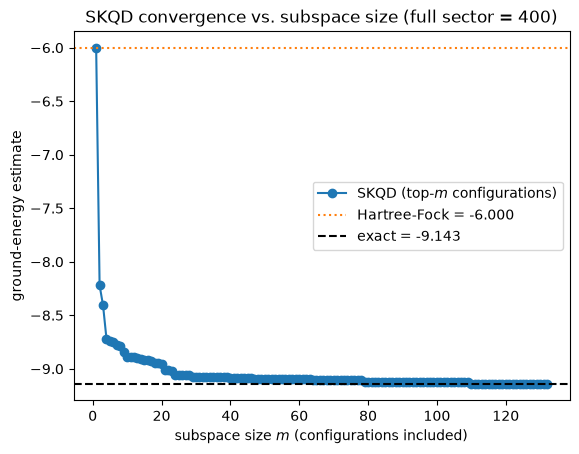

In [256]:
import matplotlib.pyplot as plt

# Hartree-Fock baseline energy <HF|H|HF> (the no-correlation reference)
E_hf = sample_based_ground_energy(H_fermion, [hf_state])

# rank the collected configurations by how often they were sampled, grow the subspace
ranked = [cfg for cfg, _ in config_counts.most_common()]
ms = list(range(1, len(ranked) + 1))
energies = [sample_based_ground_energy(H_fermion, ranked[:m]) for m in ms]

plt.figure()
plt.plot(ms, energies, "o-", label="SKQD (top-$m$ configurations)")
plt.axhline(E_hf, color="C1", ls=":", label=f"Hartree-Fock = {E_hf:.3f}")
plt.axhline(E_exact, color="k", ls="--", label=f"exact = {E_exact:.3f}")
plt.xlabel("subspace size $m$ (configurations included)")
plt.ylabel("ground-energy estimate")
plt.title(f"SKQD convergence vs. subspace size (full sector = {sector_dim})")
plt.legend()
plt.show()

## References

<a name='skqd'>[1]</a> Jeffery Yu, Javier Robledo Moreno, Joseph T. Iosue, Luke Bertels, Daniel Claudino,
Bryce Fuller, Peter Groszkowski, Travis S. Humble, Petar Jurcevic, William Kirby,
Thomas A. Maier, Mario Motta, Bibek Pokharel, Alireza Seif, Amir Shehata, Kevin J. Sung,
Minh C. Tran, Vinay Tripathi, Antonio Mezzacapo, and Kunal Sharma,
*"Quantum-Centric Algorithm for Sample-Based Krylov Diagonalization"*,
[arXiv:2501.09702](https://arxiv.org/abs/2501.09702) (2025).

<a name='kqd'>[2]</a> Nobuyuki Yoshioka, Mirko Amico, William Kirby, Petar Jurcevic, Arkopal Dutt, Bryce Fuller, Shelly Garion, Holger Haas, Ikko Hamamura, Alexander Ivrii, Ritajit Majumdar, Zlatko Minev, Mario Motta, Bibek Pokharel, Pedro Rivero, Kunal Sharma, Christopher J. Wood, Ali Javadi-Abhari, and Antonio Mezzacapo, *"Diagonalization of Large Many-Body Hamiltonians on a Quantum Processor"*, [arXiv:2407.14431](https://arxiv.org/abs/2407.14431) (2024).

<a name='sqd'>[3]</a> J. Robledo-Moreno, M. Motta, H. Haas, A. Javadi-Abhari, P. Jurcevic, W. Kirby, S. Martiel, K. Sharma, S. Sharma, T. Shirakawa, I. Sitdikov, R.-Y. Sun, K. J. Sung, M. Takita, M. C. Tran, S. Yunoki, and A. Mezzacapo, *"Chemistry Beyond the Scale of Exact Diagonalization on a Quantum-Centric Supercomputer"*, Science Advances **11**, eadu9991 (2025); [arXiv:2405.05068](https://arxiv.org/abs/2405.05068).

<a name='anderson'>[4]</a> P. W. Anderson, *"Localized Magnetic States in Metals"*, [Phys. Rev. **124**, 41 (1961)](https://doi.org/10.1103/PhysRev.124.41).